# **Kinematics regression — remove locomotion from neural responses**

The mouse runs on a ball during stimulus presentations. Locomotion modulates
cortical activity (especially V1, PPC), and different stimuli may trigger
different movement patterns. This notebook:

1. Fits a ridge regression predicting each neuron's session-level z_dff from
   ball kinematics (roll, pitch, yaw + abs values + speed, with time lags).
2. Subtracts the predicted component → **residual = stimulus-only activity**.
3. Epochs the residuals into the same trial tensor and compares raw vs
   corrected population heatmaps.

> **Caveat:** if stimuli genuinely cause movement changes that drive neural
> responses (e.g. freezing to a male), regression removes some real signal.
> Always show both raw and corrected side by side.
>
> Decoding comparisons (raw vs corrected) live in `decoding_main.ipynb`.

## Section 0 : Load data

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from neural_analysis import (NeuralAnalysis, set_style,
                             build_kinematics_design, regress_out_kinematics)
set_style(font="Arial", size=7)

# ---- EDIT ----
DATA       = "/Volumes/Akhil Data/Akhil/ProcessedData/IS-2-1L/2026-07-01"
pre_frames = 15
fs         = 15.06

# session-level continuous data
zdff_session = np.load(os.path.join(DATA, "session_zdff.npy"))
ball = dict(np.load(os.path.join(DATA, "ball_session.npz")))

# trial tensor + labels + regions (for comparison plots)
X_raw  = np.load(os.path.join(DATA, "tensor_zdff.npy"))
labels = np.load(os.path.join(DATA, "tensor_labels.npy"), allow_pickle=True)
try:
    regions = np.load(os.path.join(DATA, "neuron_regions.npy"), allow_pickle=True)
except FileNotFoundError:
    regions = None

print("session z_dff:", zdff_session.shape)
print("ball:", {k: v.shape for k, v in ball.items()})
print("trial tensor:", X_raw.shape)

session z_dff: (5352, 30000)
ball: {'roll': (30000,), 'pitch': (30000,), 'yaw': (30000,)}
trial tensor: (72, 5352, 120)


## Section 1 : Inspect ball kinematics

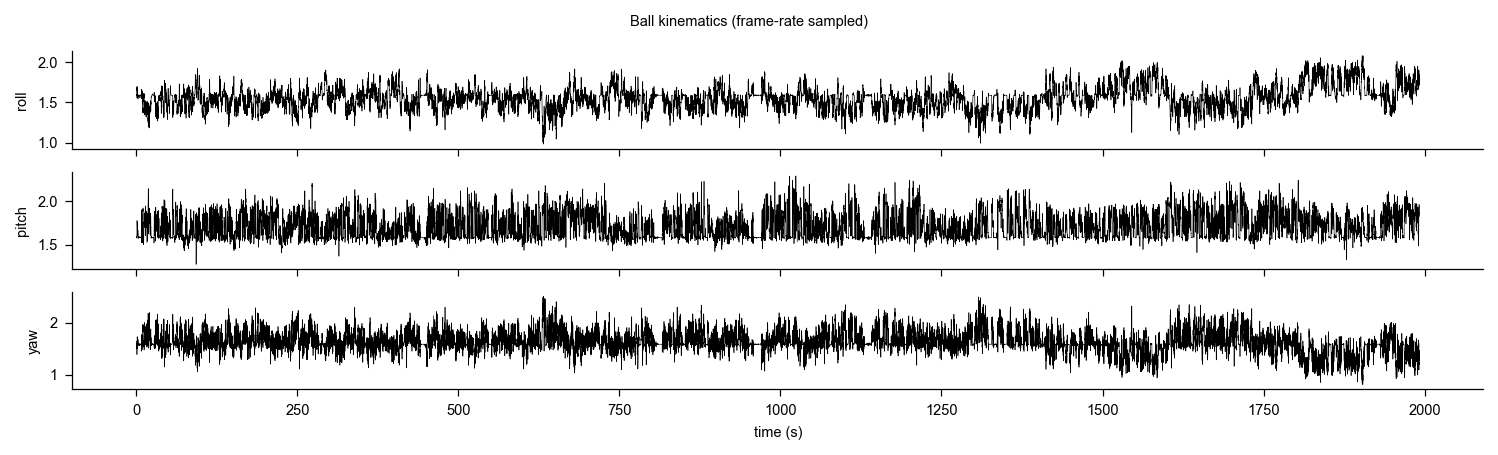

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(10, 3), sharex=True, dpi=150)
t_session = np.arange(zdff_session.shape[1]) / fs
for ax, key in zip(axes, ["roll", "pitch", "yaw"]):
    ax.plot(t_session, ball[key], lw=0.3, color="k")
    ax.set_ylabel(key, fontsize=7)
axes[-1].set_xlabel("time (s)", fontsize=7)
fig.suptitle("Ball kinematics (frame-rate sampled)", fontsize=7)
fig.tight_layout()
plt.show()

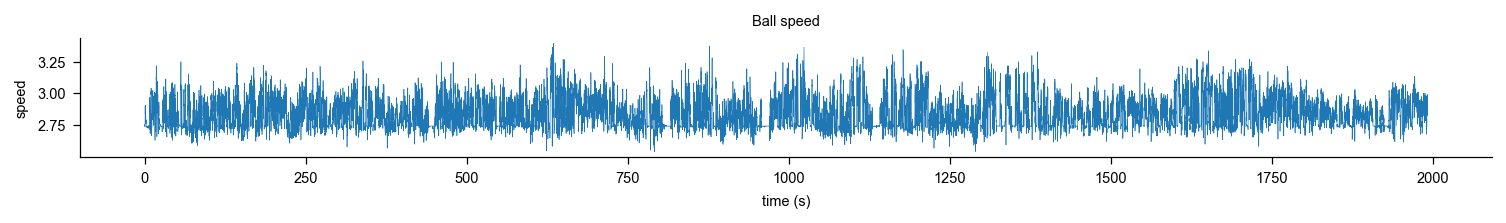

In [3]:
speed = np.sqrt(ball["roll"]**2 + ball["pitch"]**2 + ball["yaw"]**2)
fig, ax = plt.subplots(figsize=(10, 1.5), dpi=150)
ax.plot(t_session, speed, lw=0.3, color="tab:blue")
ax.set(xlabel="time (s)", ylabel="speed", title="Ball speed")
fig.tight_layout()
plt.show()

## Section 2 : Ridge regression — regress out kinematics

In [4]:
# Fit ridge regression: neuron ~ kinematics (with lags 0, 1, 2 frames = 0, 67, 133 ms)
residuals, r2, coefs, feat_names = regress_out_kinematics(
    zdff_session, ball, lags=(0, 1, 2), alpha=1.0)

print("residuals:", residuals.shape)
print(f"R² across neurons: mean={r2.mean():.4f}, median={np.median(r2):.4f}, "
      f"max={r2.max():.4f}, >5%={np.mean(r2 > 0.05)*100:.1f}% of neurons")

residuals: (5352, 30000)
R² across neurons: mean=0.0099, median=0.0066, max=0.1912, >5%=1.4% of neurons


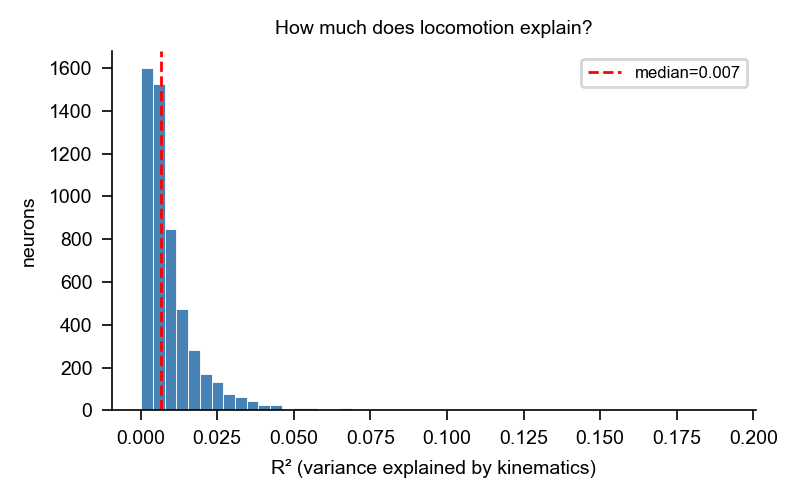

In [5]:
# R² distribution
fig, ax = plt.subplots(figsize=(4, 2.5), dpi=200)
ax.hist(r2, bins=50, color="steelblue", edgecolor="white", lw=0.3)
ax.axvline(np.median(r2), color="red", ls="--", lw=1, label=f"median={np.median(r2):.3f}")
ax.set(xlabel="R² (variance explained by kinematics)", ylabel="neurons",
       title="How much does locomotion explain?")
ax.legend(fontsize=6)
fig.tight_layout()
plt.show()

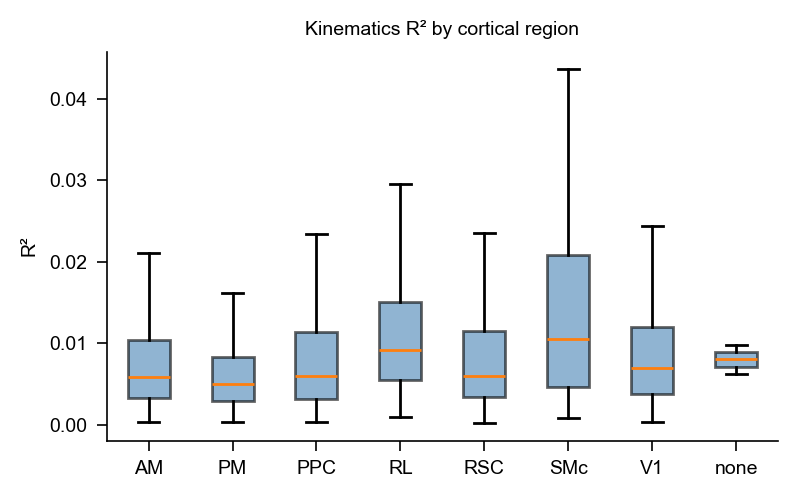

In [6]:
# R² by region
if regions is not None:
    fig, ax = plt.subplots(figsize=(4, 2.5), dpi=200)
    region_names = sorted(set(regions.tolist()))
    r2_by_reg = [r2[regions == r] for r in region_names]
    bp = ax.boxplot(r2_by_reg, labels=region_names, showfliers=False, patch_artist=True)
    for patch in bp["boxes"]:
        patch.set_facecolor("steelblue")
        patch.set_alpha(0.6)
    ax.set(ylabel="R²", title="Kinematics R² by cortical region")
    fig.tight_layout()
    plt.show()

## Section 3 : Epoch residuals into trial tensor

In [7]:
# Load trial info to get onset frames
import pandas as pd
trial_df = pd.read_csv(os.path.join(DATA, "trials_info.csv"))
onset_frames = trial_df["onset_frame"].values
n_frames_total = pre_frames + (X_raw.shape[2] - pre_frames)  # 120
n_forward = X_raw.shape[2] - pre_frames  # 105

# Epoch residuals into the same trial structure
n_trials = len(onset_frames)
n_neurons = residuals.shape[0]
X_corr = np.zeros((n_trials, n_neurons, n_frames_total))
for i, f in enumerate(onset_frames):
    start = f - pre_frames
    end = f + n_forward
    X_corr[i] = residuals[:, start:end]

# Baseline correct the corrected tensor
bl = X_corr[:, :, :pre_frames].mean(axis=2, keepdims=True)
X_corr = X_corr - bl

print("corrected tensor:", X_corr.shape)
np.save(os.path.join(DATA, "tensor_zdff_corrected.npy"), X_corr)

corrected tensor: (72, 5352, 120)


## Section 4 : Compare raw vs corrected — population heatmaps

--- RAW ---


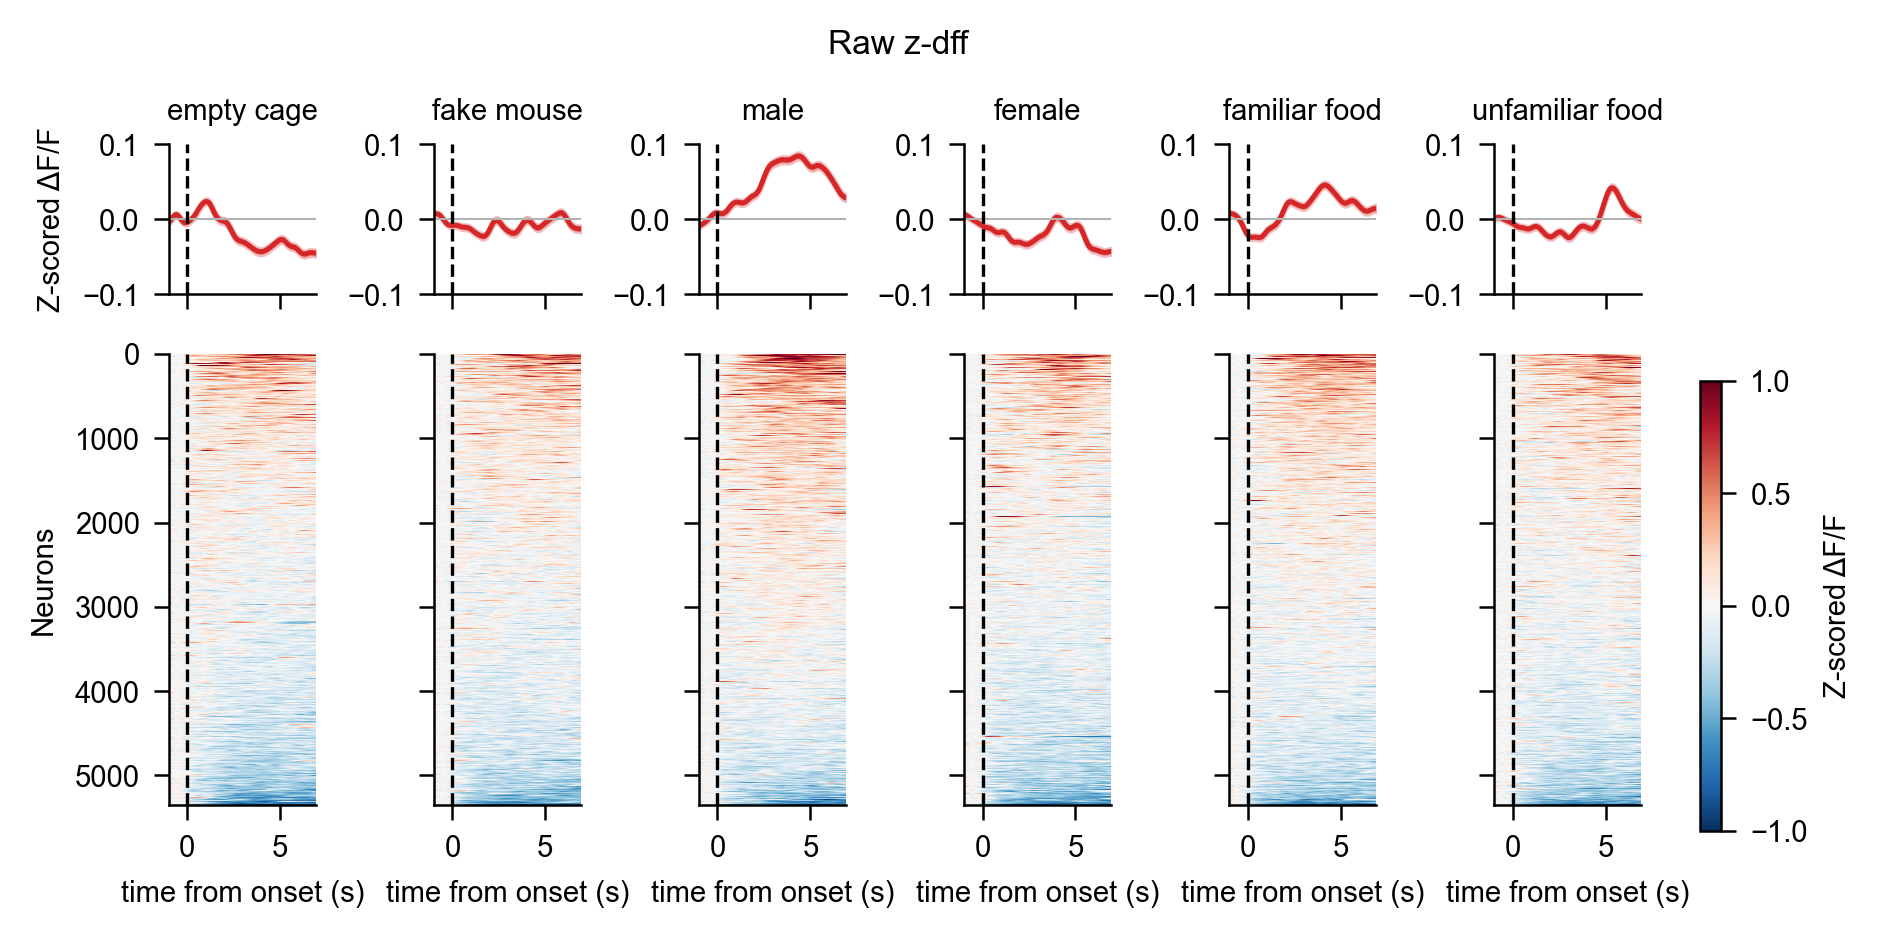

--- KINEMATICS CORRECTED ---


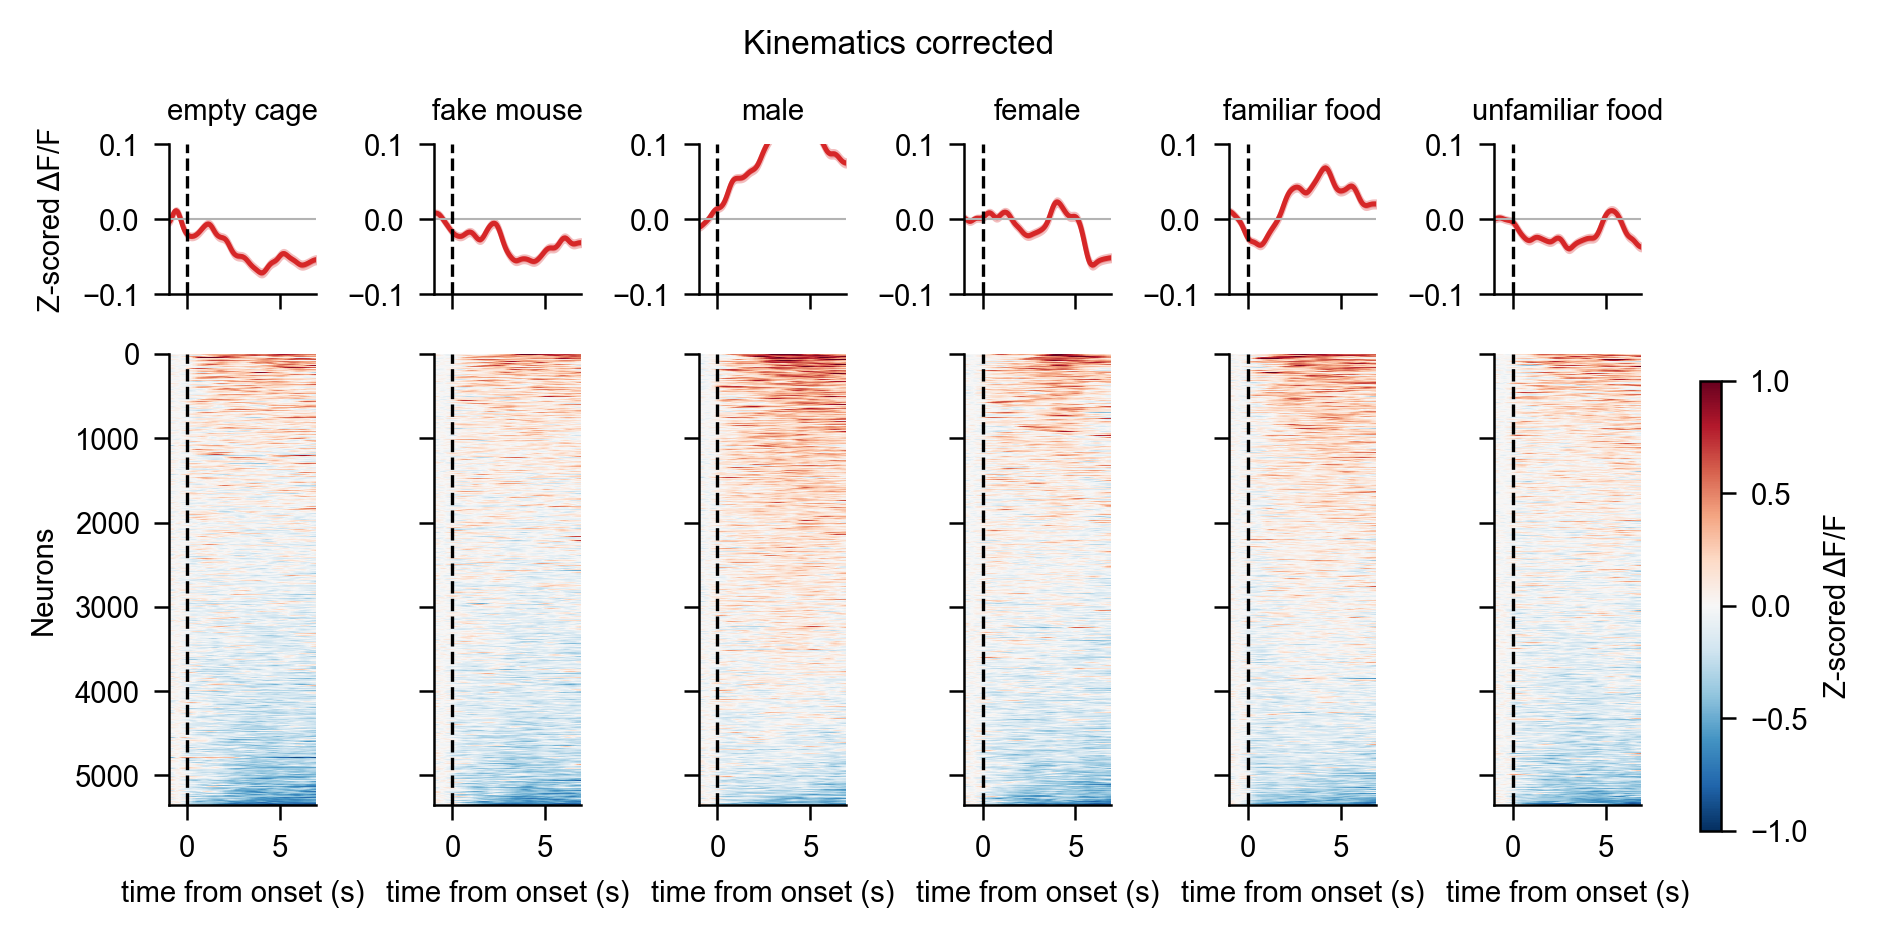

In [8]:
na_raw  = NeuralAnalysis(X_raw,  labels, regions=regions, fs=fs, pre_frames=pre_frames)
na_corr = NeuralAnalysis(X_corr, labels, regions=regions, fs=fs, pre_frames=pre_frames)

print("--- RAW ---")
fig = na_raw.plot_population_heatmap(clip=1.0, figsize=(6, 3), dpi=300, smooth_sigma=3)
fig.suptitle("Raw z-dff", fontsize=8, y=1.01)
plt.show()

print("--- KINEMATICS CORRECTED ---")
fig = na_corr.plot_population_heatmap(clip=1.0, figsize=(6, 3), dpi=300, smooth_sigma=3)
fig.suptitle("Kinematics corrected", fontsize=8, y=1.01)
plt.show()

## Section 5 : Ball kinematics by stimulus

Check whether different stimuli evoke different movement patterns — if so,
the regression is removing a real stimulus-movement coupling.

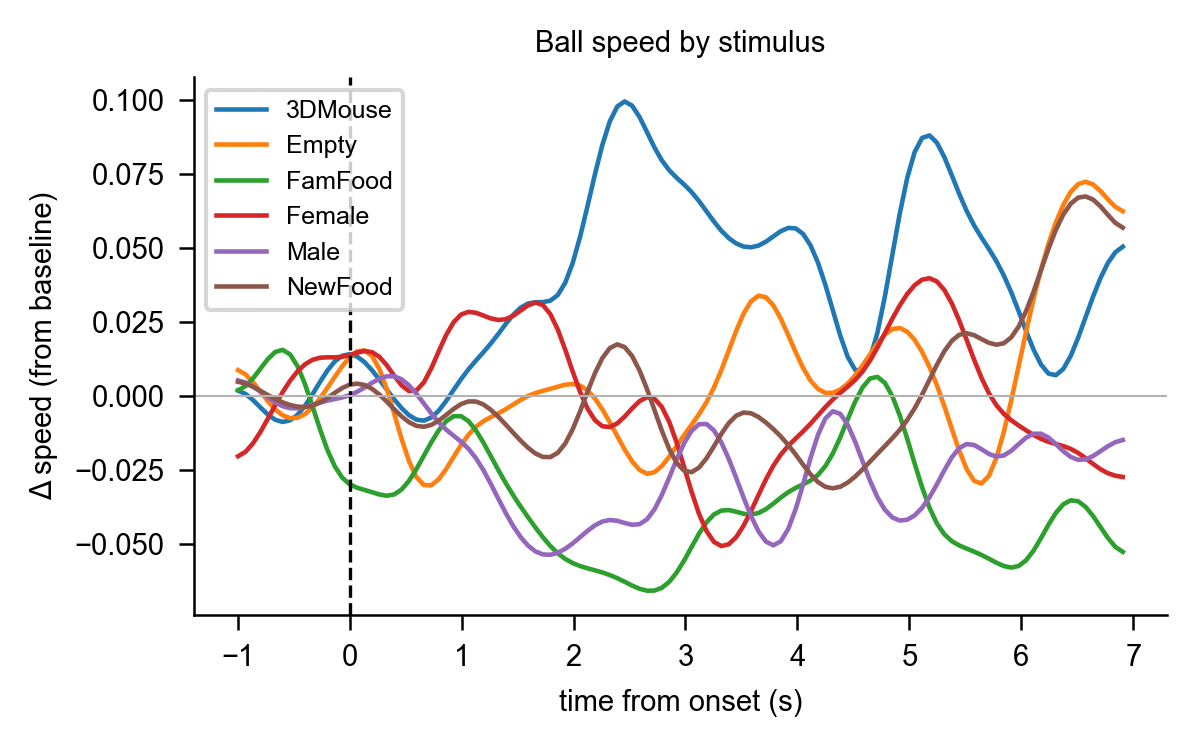

In [9]:
# Epoch ball speed into the same trial windows
speed_session = np.sqrt(ball["roll"]**2 + ball["pitch"]**2 + ball["yaw"]**2)
speed_trials = np.zeros((len(onset_frames), n_frames_total))
for i, f in enumerate(onset_frames):
    speed_trials[i] = speed_session[f - pre_frames : f + n_forward]

# Baseline correct speed
speed_bl = speed_trials[:, :pre_frames].mean(axis=1, keepdims=True)
speed_trials_bc = speed_trials - speed_bl

time = (np.arange(n_frames_total) - pre_frames) / fs
fig, ax = plt.subplots(figsize=(4, 2.5), dpi=300)
from scipy.ndimage import gaussian_filter1d
for stim in sorted(set(labels)):
    mask = labels == stim
    m = gaussian_filter1d(speed_trials_bc[mask].mean(0), sigma=3)
    ax.plot(time, m, lw=1.1, label=stim)
ax.axvline(0, color="k", ls="--", lw=0.8)
ax.axhline(0, color="0.7", lw=0.5)
ax.set(xlabel="time from onset (s)", ylabel="Δ speed (from baseline)",
       title="Ball speed by stimulus")
ax.legend(fontsize=6)
fig.tight_layout()
plt.show()